In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Phillips curve

In [2]:
# Load data
df_cpi = pd.read_csv('data/CPIAUCSL.csv', index_col='observation_date', parse_dates=True)
df_unemp = pd.read_csv('data/UNRATE.csv', index_col='observation_date', parse_dates=True)

# Merge and interpolate missing values in Oct 2025
df = df_cpi.join(df_unemp, how='inner').interpolate()

# Compute annual inflation (log change vs. 12 months ago)
df['inflation'] = 100 * (np.log(df['CPIAUCSL']) - np.log(df['CPIAUCSL'].shift(12)))
df = df.dropna()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


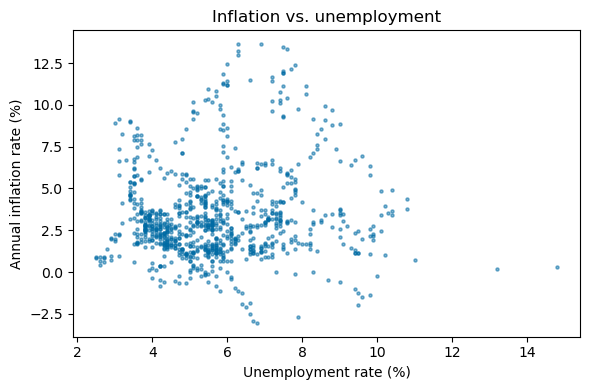

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df['UNRATE'], df['inflation'], s=5, alpha=0.5, color='C0')
ax.set_xlabel('Unemployment rate (%)')
ax.set_ylabel('Annual inflation rate (%)')
ax.set_title('Inflation vs. unemployment')
plt.tight_layout()
fig.savefig('output/scatter_infl_unemp.eps')
plt.show()

In [4]:
# OLS regression of inflation on unemployment with heteroskedasticity-robust SE
X = sm.add_constant(df['UNRATE'])
model = sm.OLS(df['inflation'], X).fit(cov_type='HC1')
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              inflation   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     4.746
Date:                Wed, 03 Jun 2026   Prob (F-statistic):             0.0296
Time:                        14:01:01   Log-Likelihood:                -2227.8
No. Observations:                 926   AIC:                             4460.
Df Residuals:                     924   BIC:                             4469.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.6917      0.295      9.119      0.0

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


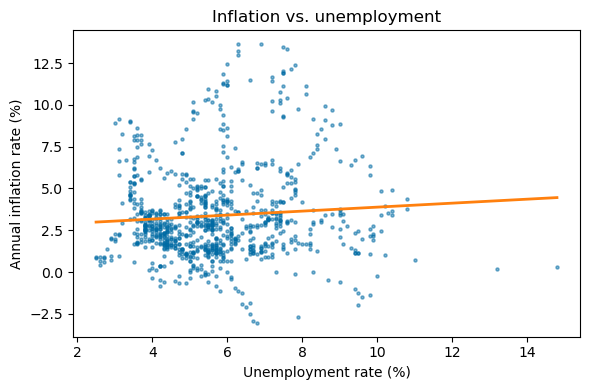

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df['UNRATE'], df['inflation'], s=5, alpha=0.5, color='C0')
x_grid = np.linspace(df['UNRATE'].min(), df['UNRATE'].max(), 100)
ax.plot(x_grid, model.params['const'] + model.params['UNRATE'] * x_grid, color='C1', linewidth=2)
ax.set_xlabel('Unemployment rate (%)')
ax.set_ylabel('Annual inflation rate (%)')
ax.set_title('Inflation vs. unemployment')
plt.tight_layout()
fig.savefig('output/scatter_infl_unemp_ols.eps')
plt.show()

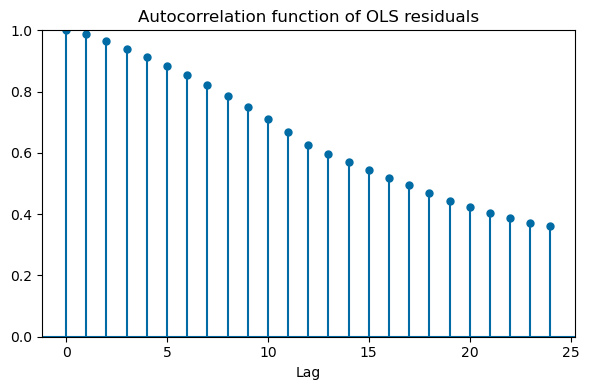

In [6]:
# Correlogram of OLS residuals
n_lags = 24
fig, ax = plt.subplots(figsize=(6, 4))
sm.graphics.tsa.plot_acf(model.resid, lags=n_lags, alpha=None, color='C0', ax=ax)
ax.set_ylim([0, 1])
ax.set_xlabel('Lag')
ax.set_title('Autocorrelation function of OLS residuals')
plt.tight_layout()
fig.savefig('output/acf_resid.eps')
plt.show()

In [7]:
# OLS regression with Newey-West SE
T_nw = model.nobs
nw_bw = int(np.ceil(0.75 * T_nw**(1/3)))
model_nw = sm.OLS(df['inflation'], X).fit(cov_type='HAC', cov_kwds={'maxlags': nw_bw-1})
print(model_nw.summary())

                            OLS Regression Results                            
Dep. Variable:              inflation   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                    0.7345
Date:                Wed, 03 Jun 2026   Prob (F-statistic):              0.392
Time:                        14:01:01   Log-Likelihood:                -2227.8
No. Observations:                 926   AIC:                             4460.
Df Residuals:                     924   BIC:                             4469.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.6917      0.743      3.622      0.0

In [8]:
# Load oil price data and compute 12-month log change
df_oil = pd.read_csv('data/WTISPLC.csv', index_col='observation_date', parse_dates=True)
df_oil['oil_change'] = 100 * (np.log(df_oil['WTISPLC']) - np.log(df_oil['WTISPLC'].shift(12)))

# Merge with existing data
df2 = df.join(df_oil[['oil_change']], how='inner').dropna()

# Expanded OLS regression
X2 = sm.add_constant(df2[['UNRATE', 'oil_change']])
model_nw2 = sm.OLS(df2['inflation'], X2).fit(cov_type='HAC', cov_kwds={'maxlags': nw_bw-1})
print(model_nw2.summary())

                            OLS Regression Results                            
Dep. Variable:              inflation   R-squared:                       0.235
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     17.19
Date:                Wed, 03 Jun 2026   Prob (F-statistic):           4.70e-08
Time:                        14:01:01   Log-Likelihood:                -2106.7
No. Observations:                 926   AIC:                             4219.
Df Residuals:                     923   BIC:                             4234.
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.9934      0.737      2.705      0.0

## AR(1) simulations

$y_t = \rho y_{t-1} + u_t,\quad u_t \overset{iid}{\sim} N(0,1)$

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


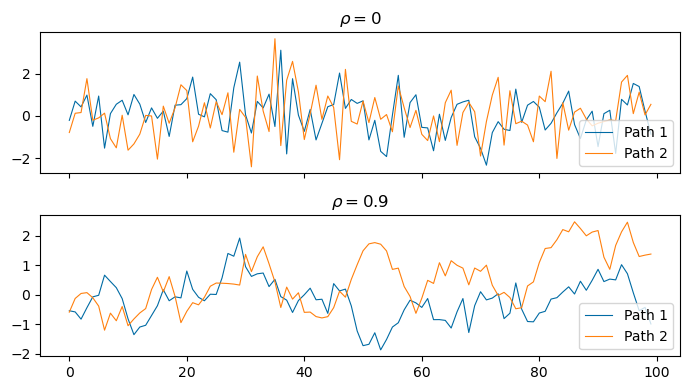

In [9]:
T = 100
rho_vals = [0, 0.9]
n_paths = 2
rng = np.random.default_rng(31150)

fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
for i, rho in enumerate(rho_vals):
    scale = np.sqrt(1 - rho**2)
    for j in range(n_paths):
        y = np.empty(T)
        y[0] = rng.normal()
        for t in range(1, T):
            y[t] = rho * y[t-1] + scale * rng.normal()
        axes[i].plot(y, linewidth=0.8, label=f'Path {j+1}')
    axes[i].set_title(f'$\\rho = {rho}$')
    axes[i].legend(loc='lower right')
plt.tight_layout()
fig.savefig('output/ar1_sim.eps')
plt.show()